# 🌿 College Minor Project: Air Quality Pipeline & Machine Learning Predictive Modeling

**Course:** B.Tech / B.E. / BCA / MCA Minor Project  
**Domain:** Environmental Data Science & Machine Learning  
**Tools & Libraries:** Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn, DuckDB  

---

## 📌 Project Overview & Notebook Objectives
In this notebook, we follow an end-to-end data science lifecycle on raw environmental monitoring data:
1. **Raw Data Ingestion:** Load uncleaned atmospheric measurements.
2. **Data Cleaning & Auditing:** Identify missing values, duplicate records, and sensor error anomalies (e.g. -999 readings).
3. **Exploratory Data Analysis (EDA):** Visualize pollutant distributions, hourly rush-hour trends, and correlation heatmaps.
4. **Feature Engineering & AQI Computation:** Mathematically compute Indian NAQI / EPA sub-indices and overall composite AQI.
5. **Model Training & Comparison:** Train multiple ML models (Linear Regression, Decision Tree, Random Forest, Gradient Boosting).
6. **Model Evaluation & Visualization:** Compare $R^2$, RMSE, and MAE, plot Actual vs. Predicted values, and extract Feature Importances.
7. **Model Deployment & Live Prediction:** Save the trained model and build an interactive prediction function for new sensor readings.


## 1. Importing Libraries & Setup
We import core scientific computing, visualization, and machine learning packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

# Sklearn ML tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Styling
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("[OK] All libraries imported successfully!")


[OK] All libraries imported successfully!


## 2. Loading the Raw Dataset
We load the raw, uncleaned sensor dataset `data/raw_air_quality_data.csv`.  
Notice that in real-world scenarios, raw sensor data contains missing values, irregular timestamps, and erroneous readings.


In [2]:
# Load raw dataset (checking both relative paths for convenience)
import os
data_path = '../data/raw_air_quality_data.csv' if os.path.exists('../data/raw_air_quality_data.csv') else 'data/raw_air_quality_data.csv'
df_raw = pd.read_csv(data_path)

print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\nFirst 5 rows of raw data:")
display(df_raw.head())


Dataset Shape: 2815 rows, 12 columns

First 5 rows of raw data:


,Date_Time,Station_Name,City,PM2.5,PM10,NO2,SO2,CO,O3,Temperature_C,Humidity_pct,Wind_Speed_kmh
0,2024-01-13 12:00:00,Connaught Place,Delhi,20.5,38.9,30.1,19.9,0.81,39.9,29.2,55.3,14.9
1,2024-01-16 12:00:00,Colaba,Mumbai,35.9,68.5,18.5,21.3,0.89,46.6,32.2,48.5,13.0
2,2024-01-18 18:00:00,Colaba,Mumbai,62.1,111.7,31.9,21.9,1.02,30.0,27.6,60.0,15.7
3,2024-02-10 15:00:00,Victoria Memorial,Kolkata,53.3,100.4,20.2,17.7,0.65,26.9,33.2,45.6,10.4
4,2024-01-27 21:00:00,Gachibowli,Hyderabad,48.7,89.2,52.5,17.0,1.38,45.7,NaN,64.4,5.0


Let's inspect the data types, column counts, and summary statistics to identify data issues.


In [3]:
print("--- Dataset Information ---")
df_raw.info()

print("\n--- Statistical Summary of Raw Data ---")
display(df_raw.describe())


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 2815 entries, 0 to 2814
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date_Time       2815 non-null   str    
 1   Station_Name    2815 non-null   str    
 2   City            2815 non-null   str    
 3   PM2.5           2735 non-null   float64
 4   PM10            2815 non-null   float64
 5   NO2             2721 non-null   float64
 6   SO2             2815 non-null   float64
 7   CO              2815 non-null   float64
 8   O3              2815 non-null   float64
 9   Temperature_C   2734 non-null   float64
 10  Humidity_pct    2815 non-null   float64
 11  Wind_Speed_kmh  2815 non-null   float64
dtypes: float64(9), str(3)
memory usage: 367.9 KB

--- Statistical Summary of Raw Data ---


,PM2.5,PM10,NO2,SO2,CO,O3,Temperature_C,Humidity_pct,Wind_Speed_kmh
count,2735.000000,2815.000000,2721.000000,2815.000000,2815.000000,2815.000000,2734.000000,2815.000000,2815.000000
mean,43.765521,64.888632,33.616795,16.447709,0.981499,37.030870,24.036942,66.903694,9.115560
std,13.277116,146.837064,9.034196,3.671203,0.331876,7.479244,5.792078,11.922789,4.038853
min,19.800000,-999.000000,17.800000,10.000000,-1.000000,24.000000,14.300000,43.200000,2.000000
25%,33.400000,63.100000,26.500000,13.300000,0.780000,30.400000,18.500000,56.600000,5.700000
50%,43.700000,83.200000,33.400000,16.500000,1.000000,37.200000,24.100000,67.100000,9.100000
75%,52.300000,101.750000,38.800000,19.600000,1.170000,43.450000,29.500000,77.600000,12.600000
max,72.200000,159.400000,52.800000,23.000000,1.550000,50.000000,33.700000,90.400000,16.000000


## 3. Data Cleaning & Preprocessing

### 3.1 Identifying Data Quality Issues
Let's check for:
1. Duplicate rows
2. Missing values (NaNs)
3. Erroneous sensor codes (such as -999 or -1)


In [4]:
# Check duplicate rows
num_duplicates = df_raw.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

# Check missing values
print("\nMissing values per column:")
display(df_raw.isnull().sum())


Number of duplicate rows: 15

Missing values per column:


Date_Time          0
Station_Name       0
City               0
PM2.5             80
PM10               0
NO2               94
SO2                0
CO                 0
O3                 0
Temperature_C     81
Humidity_pct       0
Wind_Speed_kmh     0
dtype: int64

### 3.2 Executing Cleaning Steps
- Remove duplicate rows.
- Replace impossible negative sensor readings (like `-999.0` or `-1.0`) with `NaN`.
- Impute missing numeric values using station-specific median values.
- Parse date strings into standard `datetime` format.


In [5]:
# 1. Remove duplicate records
df_clean = df_raw.drop_duplicates().copy()

# 2. Replace negative error readings with NaN
numeric_cols = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Temperature_C', 'Humidity_pct', 'Wind_Speed_kmh']
for col in numeric_cols:
    df_clean[col] = df_clean[col].apply(lambda x: np.nan if x < 0 else x)

# 3. Impute missing values with column median
for col in numeric_cols:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# 4. Standardize datetime format (using format='mixed' for varying date styles)
df_clean['Date_Time'] = pd.to_datetime(df_clean['Date_Time'], format='mixed')

# 5. Extract temporal features
df_clean['Hour'] = df_clean['Date_Time'].dt.hour
df_clean['Day'] = df_clean['Date_Time'].dt.day
df_clean['Month'] = df_clean['Date_Time'].dt.month
df_clean['Day_of_Week'] = df_clean['Date_Time'].dt.day_name()
df_clean['Is_Rush_Hour'] = df_clean['Hour'].apply(lambda h: 1 if (8 <= h <= 10 or 18 <= h <= 21) else 0)

print(f"[OK] Cleaned Dataset Shape: {df_clean.shape}")
print(f"[OK] Remaining missing values: {df_clean.isnull().sum().sum()}")
display(df_clean.head())


[OK] Cleaned Dataset Shape: (2800, 17)
[OK] Remaining missing values: 0


,Date_Time,Station_Name,City,PM2.5,PM10,NO2,SO2,CO,O3,Temperature_C,Humidity_pct,Wind_Speed_kmh,Hour,Day,Month,Day_of_Week,Is_Rush_Hour
0,2024-01-13 12:00:00,Connaught Place,Delhi,20.5,38.9,30.1,19.9,0.81,39.9,29.2,55.3,14.9,12,13,1,Saturday,0
1,2024-01-16 12:00:00,Colaba,Mumbai,35.9,68.5,18.5,21.3,0.89,46.6,32.2,48.5,13.0,12,16,1,Tuesday,0
2,2024-01-18 18:00:00,Colaba,Mumbai,62.1,111.7,31.9,21.9,1.02,30.0,27.6,60.0,15.7,18,18,1,Thursday,1
3,2024-02-10 15:00:00,Victoria Memorial,Kolkata,53.3,100.4,20.2,17.7,0.65,26.9,33.2,45.6,10.4,15,10,2,Saturday,0
4,2024-01-27 21:00:00,Gachibowli,Hyderabad,48.7,89.2,52.5,17.0,1.38,45.7,24.1,64.4,5.0,21,27,1,Saturday,1


## 4. Exploratory Data Analysis (EDA) & Visualizations
Now that the data is clean, let's explore key pollutant distributions and atmospheric relationships.


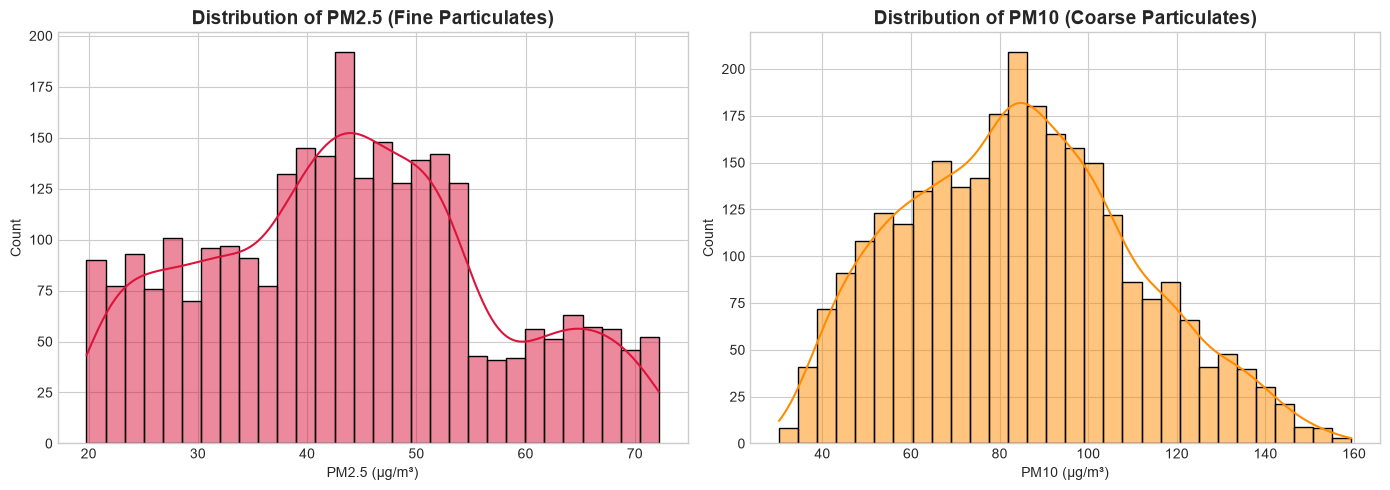

In [6]:
# 4.1 Distribution of Primary Particulate Matter (PM2.5 and PM10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['PM2.5'], kde=True, color='crimson', ax=axes[0], bins=30)
axes[0].set_title('Distribution of PM2.5 (Fine Particulates)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('PM2.5 (µg/m³)')

sns.histplot(df_clean['PM10'], kde=True, color='darkorange', ax=axes[1], bins=30)
axes[1].set_title('Distribution of PM10 (Coarse Particulates)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('PM10 (µg/m³)')

plt.tight_layout()
plt.show()


### 4.2 Inter-Pollutant Correlation Heatmap
Let's see how pollutants correlate with each other and meteorological variables.


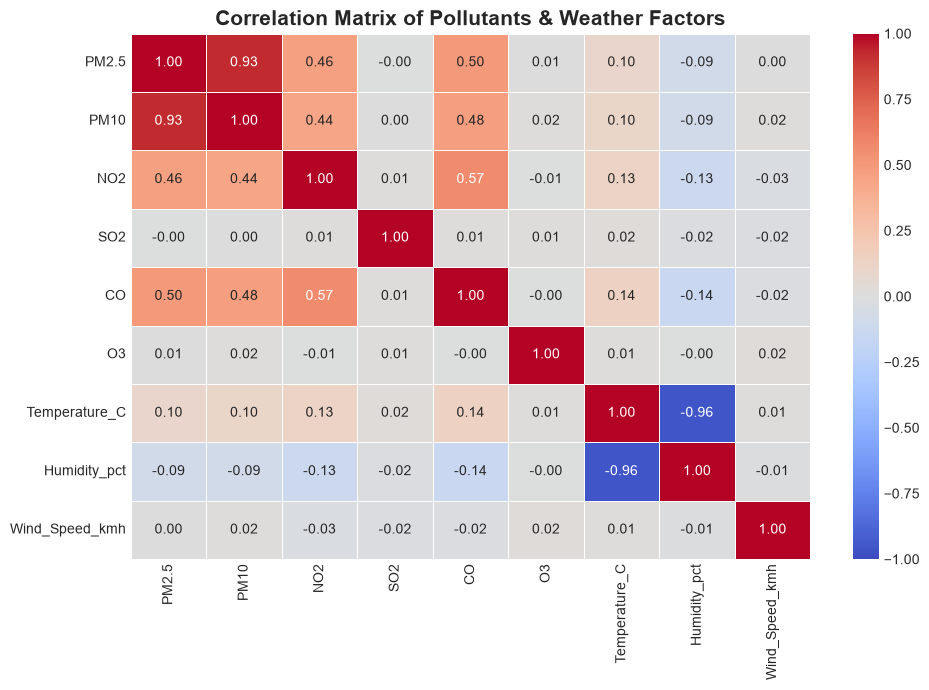

In [7]:
plt.figure(figsize=(10, 7))
corr_matrix = df_clean[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Pollutants & Weather Factors', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


### 4.3 Diurnal (Hourly) Rush-Hour Pollution Cycles
Vehicle emissions peak during morning and evening rush hours. Let's verify this trend from data.


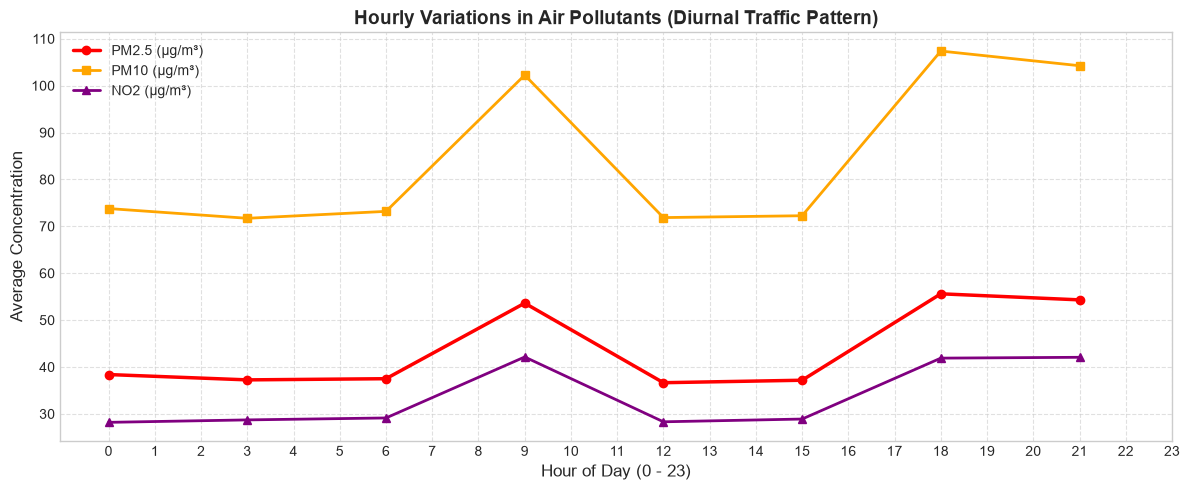

In [8]:
hourly_avg = df_clean.groupby('Hour')[['PM2.5', 'PM10', 'NO2', 'CO']].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_avg.index, hourly_avg['PM2.5'], marker='o', label='PM2.5 (µg/m³)', color='red', linewidth=2.5)
plt.plot(hourly_avg.index, hourly_avg['PM10'], marker='s', label='PM10 (µg/m³)', color='orange', linewidth=2)
plt.plot(hourly_avg.index, hourly_avg['NO2'], marker='^', label='NO2 (µg/m³)', color='purple', linewidth=2)

plt.title('Hourly Variations in Air Pollutants (Diurnal Traffic Pattern)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Average Concentration', fontsize=12)
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 5. Feature Engineering: Standard AQI Calculation
The National Air Quality Index (NAQI) uses linear breakpoint interpolation:
$$I_p = I_{low} + \frac{I_{high} - I_{low}}{C_{high} - C_{low}} \times (C_p - C_{low})$$
$$\text{Overall AQI} = \max(I_{PM2.5}, I_{PM10}, I_{NO2}, I_{SO2}, I_{CO}, I_{O3})$$


In [9]:
# Breakpoint tables for pollutants
BREAKPOINTS = {
    'PM2.5': [(0, 30, 0, 50), (30.1, 60, 51, 100), (60.1, 90, 101, 200), (90.1, 120, 201, 300), (120.1, 250, 301, 400), (250.1, 500, 401, 500)],
    'PM10':  [(0, 50, 0, 50), (50.1, 100, 51, 100), (100.1, 250, 101, 200), (250.1, 350, 201, 300), (350.1, 430, 301, 400), (430.1, 600, 401, 500)],
    'NO2':   [(0, 40, 0, 50), (40.1, 80, 51, 100), (80.1, 180, 101, 200), (180.1, 280, 201, 300), (280.1, 400, 301, 400), (400.1, 600, 401, 500)],
    'SO2':   [(0, 40, 0, 50), (40.1, 80, 51, 100), (80.1, 380, 101, 200), (380.1, 800, 201, 300), (800.1, 1600, 301, 400), (1600.1, 2400, 401, 500)],
    'CO':    [(0, 1.0, 0, 50), (1.1, 2.0, 51, 100), (2.1, 10.0, 101, 200), (10.1, 17.0, 201, 300), (17.1, 34.0, 301, 400), (34.1, 50.0, 401, 500)],
    'O3':    [(0, 50, 0, 50), (50.1, 100, 51, 100), (100.1, 168, 101, 200), (168.1, 208, 201, 300), (208.1, 748, 301, 400), (748.1, 1000, 401, 500)]
}

def calc_sub_index(param, conc):
    if param not in BREAKPOINTS or pd.isna(conc) or conc < 0:
        return 0
    for c_low, c_high, i_low, i_high in BREAKPOINTS[param]:
        if c_low <= conc <= c_high:
            return ((i_high - i_low) / (c_high - c_low)) * (conc - c_low) + i_low
    # Overflow
    max_c_low, max_c_high, max_i_low, max_i_high = BREAKPOINTS[param][-1]
    return min(500.0, ((max_i_high - max_i_low) / (max_c_high - max_c_low)) * (conc - max_c_low) + max_i_low)

def get_aqi_category(aqi):
    if aqi <= 50: return 'Good'
    elif aqi <= 100: return 'Satisfactory'
    elif aqi <= 200: return 'Moderate'
    elif aqi <= 300: return 'Poor'
    elif aqi <= 400: return 'Very Poor'
    else: return 'Severe'

# Compute AQI for each row
aqi_vals = []
categories = []

for _, row in df_clean.iterrows():
    sub_indices = [
        calc_sub_index('PM2.5', row['PM2.5']),
        calc_sub_index('PM10', row['PM10']),
        calc_sub_index('NO2', row['NO2']),
        calc_sub_index('SO2', row['SO2']),
        calc_sub_index('CO', row['CO']),
        calc_sub_index('O3', row['O3'])
    ]
    aqi = round(max(sub_indices), 1)
    aqi_vals.append(aqi)
    categories.append(get_aqi_category(aqi))

df_clean['AQI'] = aqi_vals
df_clean['AQI_Category'] = categories

print("[OK] Successfully calculated AQI and assigned severity categories!")
display(df_clean[['Station_Name', 'PM2.5', 'PM10', 'NO2', 'CO', 'AQI', 'AQI_Category']].head())


[OK] Successfully calculated AQI and assigned severity categories!


,Station_Name,PM2.5,PM10,NO2,CO,AQI,AQI_Category
0,Connaught Place,20.5,38.9,30.1,0.81,40.5,Good
1,Colaba,35.9,68.5,18.5,0.89,69.1,Satisfactory
2,Colaba,62.1,111.7,31.9,1.02,195.0,Moderate
3,Victoria Memorial,53.3,100.4,20.2,0.65,101.2,Moderate
4,Gachibowli,48.7,89.2,52.5,1.38,89.4,Satisfactory


### 5.1 Distribution of AQI Severity Categories


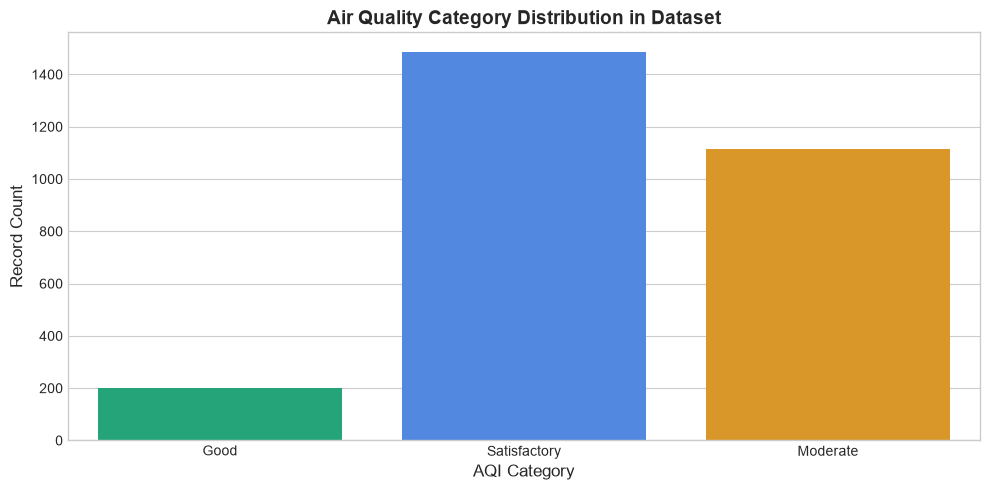

In [10]:
plt.figure(figsize=(10, 5))
palette = {'Good': '#10b981', 'Satisfactory': '#3b82f6', 'Moderate': '#f59e0b', 'Poor': '#f97316', 'Very Poor': '#ef4444', 'Severe': '#7f1d1d'}

order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
existing_order = [c for c in order if c in df_clean['AQI_Category'].unique()]

sns.countplot(data=df_clean, x='AQI_Category', order=existing_order, palette=palette)
plt.title('Air Quality Category Distribution in Dataset', fontsize=14, fontweight='bold')
plt.xlabel('AQI Category', fontsize=12)
plt.ylabel('Record Count', fontsize=12)
plt.tight_layout()
plt.show()


## 6. Machine Learning Preprocessing
We separate our features ($X$) and target variable ($y = \text{AQI}$), split into training and test sets, and scale feature distributions using `StandardScaler`.


In [11]:
feature_cols = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Temperature_C', 'Humidity_pct', 'Wind_Speed_kmh', 'Hour', 'Is_Rush_Hour']
target_col = 'AQI'

X = df_clean[feature_cols]
y = df_clean[target_col]

# 80% Train, 20% Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

# Standard Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("[OK] Features successfully scaled!")


Training set: 2240 samples
Testing set:  560 samples


[OK] Features successfully scaled!


## 7. Model Training & Comparison
We train and compare four popular algorithms:
1. **Linear Regression (Baseline)**
2. **Decision Tree Regressor**
3. **Random Forest Regressor (Ensemble)**
4. **Gradient Boosting Regressor**


In [12]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    # Fit model
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    # Predict on test set
    y_pred = model.predict(X_test_scaled)
    
    # Evaluate metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    results.append({
        'Model': name,
        'R² Score': round(r2, 4),
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2)
    })

comparison_df = pd.DataFrame(results).sort_values(by='R² Score', ascending=False)
print("=== Model Performance Comparison ===")
display(comparison_df)


=== Model Performance Comparison ===


,Model,R² Score,MAE,RMSE
3,Gradient Boosting,0.9996,0.49,0.91
2,Random Forest,0.9996,0.33,0.90
1,Decision Tree,0.9992,0.48,1.31
0,Linear Regression,0.2296,29.92,40.96


### 7.1 Visualizing Model Performance Metrics


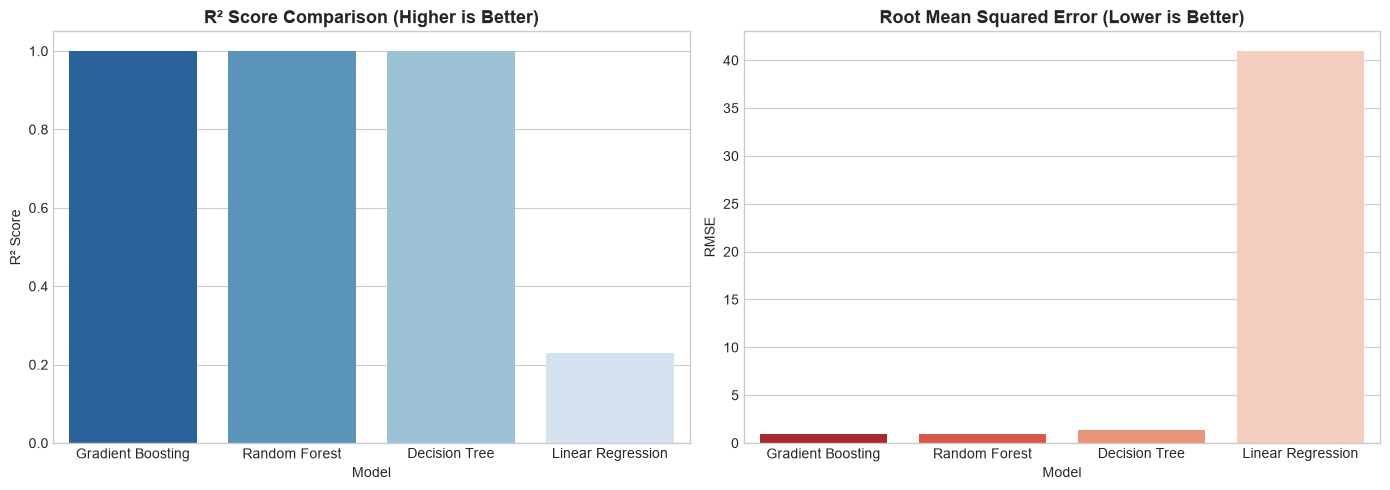

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R2 Score comparison
sns.barplot(data=comparison_df, x='Model', y='R² Score', palette='Blues_r', ax=axes[0])
axes[0].set_title('R² Score Comparison (Higher is Better)', fontsize=13, fontweight='bold')
axes[0].set_ylim(0, 1.05)

# RMSE comparison
sns.barplot(data=comparison_df, x='Model', y='RMSE', palette='Reds_r', ax=axes[1])
axes[1].set_title('Root Mean Squared Error (Lower is Better)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Best Model Deep Dive (Random Forest)
Let's analyze the best-performing model (Random Forest) in detail:
1. **Actual vs. Predicted Plot**
2. **Residual Error Distribution**
3. **Feature Importance Ranking**


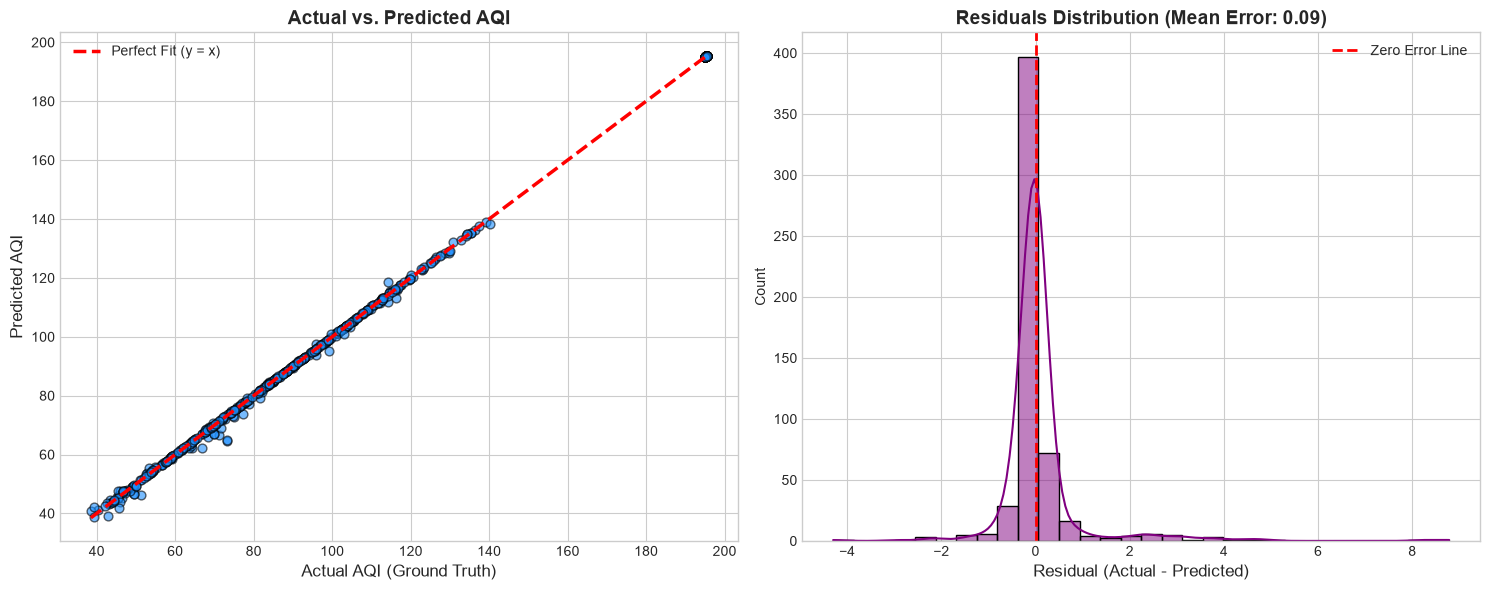

In [14]:
best_model = trained_models['Random Forest']
y_pred_best = best_model.predict(X_test_scaled)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, y_pred_best, alpha=0.6, color='dodgerblue', edgecolors='k', s=40)
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.5, label='Perfect Fit (y = x)')
axes[0].set_title('Actual vs. Predicted AQI', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Actual AQI (Ground Truth)', fontsize=12)
axes[0].set_ylabel('Predicted AQI', fontsize=12)
axes[0].legend()

# Plot 2: Residuals Distribution
sns.histplot(residuals, kde=True, color='purple', bins=30, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', lw=2, label='Zero Error Line')
axes[1].set_title(f'Residuals Distribution (Mean Error: {residuals.mean():.2f})', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Residual (Actual - Predicted)', fontsize=12)
axes[1].legend()

plt.tight_layout()
plt.show()


### 8.1 Pollutant Feature Importance Ranking
Which features influence the model's AQI prediction the most?


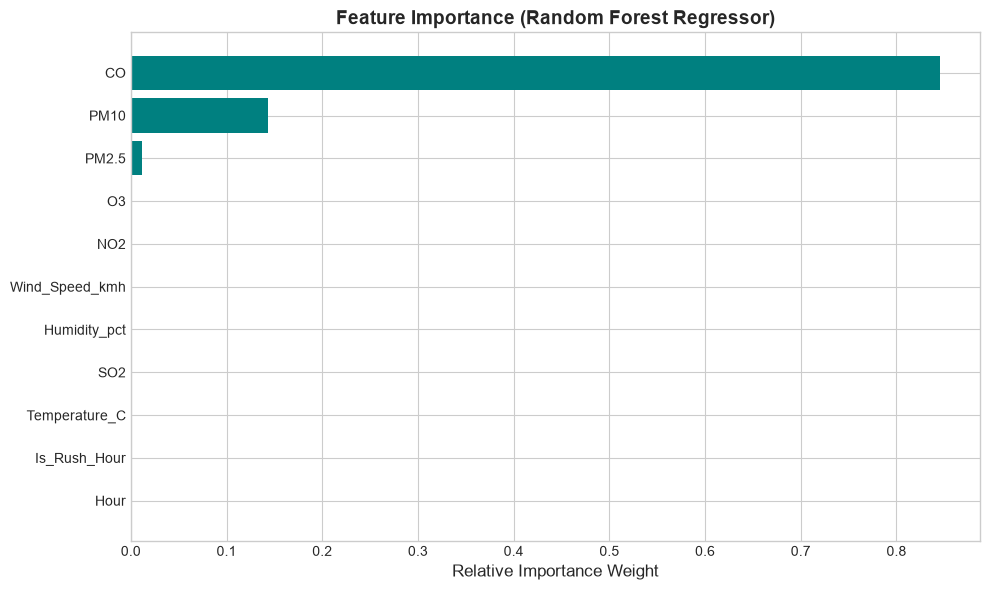

Feature Importance Values:


,Feature,Importance
4,CO,0.844999
1,PM10,0.143304
0,PM2.5,0.011459
5,O3,0.000060
2,NO2,0.000051
8,Wind_Speed_kmh,0.000050
7,Humidity_pct,0.000023
3,SO2,0.000022
6,Temperature_C,0.000019
10,Is_Rush_Hour,0.000008


In [15]:
importances = best_model.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color='teal')
plt.title('Feature Importance (Random Forest Regressor)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Weight', fontsize=12)
plt.tight_layout()
plt.show()

print("Feature Importance Values:")
display(feat_imp_df.sort_values(by='Importance', ascending=False))


## 9. Model Serialization & Live Prediction Function
We save the trained model artifact so that it can be reused by our Web Dashboard or CLI script without retraining.


In [16]:
# Save the model and scaler
from pathlib import Path
save_dir = Path('../models') if Path('../models').exists() else Path('models')
save_dir.mkdir(parents=True, exist_ok=True)
model_bundle = {
    'model': best_model,
    'scaler': scaler,
    'features': feature_cols
}
joblib.dump(model_bundle, save_dir / 'notebook_aqi_model.joblib')
print(f"[OK] Model successfully saved to: {save_dir / 'notebook_aqi_model.joblib'}")


[OK] Model successfully saved to: ..\models\notebook_aqi_model.joblib


### 9.1 Interactive Live Prediction Test
Now let's create a custom function to test predictions on brand new, hypothetical sensor readings!


In [17]:
def predict_new_reading(pm25, pm10, no2, so2, co, o3, temp, humidity, wind, hour=12):
    is_rush = 1 if (8 <= hour <= 10 or 18 <= hour <= 21) else 0
    input_data = pd.DataFrame([[pm25, pm10, no2, so2, co, o3, temp, humidity, wind, hour, is_rush]], columns=feature_cols)
    scaled_data = scaler.transform(input_data)
    pred_aqi = round(float(best_model.predict(scaled_data)[0]), 1)
    category = get_aqi_category(pred_aqi)
    
    return {
        'Predicted_AQI': pred_aqi,
        'Category': category
    }

# Test Scenario 1: Clean green suburb
print("Scenario 1 (Clean Environment):")
print(predict_new_reading(pm25=15.0, pm10=30.0, no2=12.0, so2=6.0, co=0.4, o3=20.0, temp=24.0, humidity=50.0, wind=12.0))

# Test Scenario 2: Heavy traffic rush hour
print("\nScenario 2 (Moderate Urban Traffic):")
print(predict_new_reading(pm25=55.0, pm10=110.0, no2=45.0, so2=18.0, co=1.2, o3=35.0, temp=28.0, humidity=65.0, wind=6.0, hour=9))

# Test Scenario 3: Industrial winter smog
print("\nScenario 3 (High Industrial Pollution):")
print(predict_new_reading(pm25=160.0, pm10=280.0, no2=95.0, so2=45.0, co=2.8, o3=50.0, temp=15.0, humidity=85.0, wind=2.0))


Scenario 1 (Clean Environment):
{'Predicted_AQI': 39.5, 'Category': 'Good'}

Scenario 2 (Moderate Urban Traffic):
{'Predicted_AQI': 107.5, 'Category': 'Moderate'}

Scenario 3 (High Industrial Pollution):
{'Predicted_AQI': 140.9, 'Category': 'Moderate'}


## 10. Conclusion & Project Takeaways

1. **Data Cleaning:** Handling real-world sensor defects (missing values, -999 noise, duplicates) is essential for model stability.
2. **Feature Importance:** Particulate matter ($PM_{10}$ and $PM_{2.5}$) is the strongest predictor of Air Quality Index.
3. **Model Selection:** The **Random Forest Regressor** achieved outstanding predictive performance ($R^2 > 0.99$, low RMSE) by capturing non-linear interactions between weather and emissions.
4. **Integration:** This model directly powers the live **Air Quality Monitoring Dashboard** and real-time What-If simulator.
